# Task 4 – Teil 7: Methodik, Darstellung und Interpretation

Dieses Notebook fasst die Methodik aller Teile zusammen: wie die Kenngrößen definiert sind, welche Größen in welcher Teilstudie verändert wurden, wie Beobachtungen physikalisch erklärt werden und wo die Modellgrenzen liegen. Außerdem werden für **alle** Zeitreihen die Spannungen an sämtlichen MV- und LV-Bussen und die Konvergenz vollständig ausgewertet.

## Aufgabenstellung

> *Untersuchen Sie zunächst einzelne Einflussgrößen in kontrollierten Teilstudien und danach ausgewählte Kombinationen. Definieren Sie, wie Sie Spannungsbandverletzungen, Leitungsengpässe, Verluste und Leistungsflussumkehr quantifizieren. Trennen Sie Beobachtung und physikalische Erklärung: Begründen Sie die Ergebnisse mit Leistungsfluss, Netzimpedanzen, Wirk- und Blindleistung, Transformatorübersetzung und Betriebsmittelgrenzen. Dokumentieren Sie Annahmen, Quellen, verwendete Profil- und Anlagendaten, Konvergenz sowie Modellgrenzen. Erfassen und berichten Sie bei **jedem** konvergierten Lastfluss die Spannungsbeträge (und, wo sinnvoll, Winkel) an sämtlichen MV- und LV-Bussen; einzelne Busse dürfen für Detaildiagramme hervorgehoben werden, ersetzen aber nicht die vollständige Auswertung.*

| Anforderung | Umsetzung |
|---|---|
| erst einzelne Einflussgrößen, dann Kombinationen | Abschnitt 1 (Übersicht der Teilstudien) |
| Definition der Kenngrößen | Abschnitt 2 |
| Konvergenz aller Lastflüsse | Abschnitt 3 |
| Spannungsbetrag und Winkel an allen MV- und LV-Bussen für jeden konvergierten Lastfluss | Abschnitt 4, vollständige Tabellen als CSV im Ordner `ergebnisse/` |
| Leistungsbilanz und Verluste | Abschnitt 5 |
| Beobachtung und physikalische Erklärung getrennt | Abschnitt 6 |
| Annahmen, Quellen, Profil- und Anlagendaten | Abschnitt 7 und `Task4-Datengrundlage.ipynb` |
| Modellgrenzen | Abschnitt 8 |

Voraussetzung: Die Notebooks Teil 1 bis Teil 5 wurden ausgeführt. Hier wird nichts neu gerechnet; alle Zeitreihen werden aus dem Ordner `simulations/` geladen.

## Importe

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import plots
import bewertung as bw
import auswertung as aw
from auswertung import V_MIN, V_MAX, V_PLAN_MIN, V_PLAN_MAX

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

ERGEBNISSE = Path("..") / "ergebnisse"
ERGEBNISSE.mkdir(exist_ok=True)

## 1 Teilstudien und Kombinationen

Jede Untersuchung startet von einer Kopie eines festen Ausgangsnetzes (`Simulation.copy`), sodass Vergleiche unter denselben Randbedingungen laufen. Die Tabelle zeigt, was in welchem Schritt verändert wurde und was konstant blieb:

| Teil | Ausgangsnetz | verändert | konstant | Simulationen |
|---|---|---|---|---|
| 1 Baseline | CIGRE-MV `with_der=False` | Schalterstellung S1–S3 | Lasten (BDEW-Profile), Netz | `w4_baseline_…` |
| 2 Ortsnetz | Baseline, S1–S3 offen | Anschlussbus des CIGRE-LV-Netzes (Bus 1 … 14) | MV-Netz, Lasten | `w4_lv_Bus…` |
| 3 Auslegung | Ortsnetz an Bus 12 | Ortsnetztrafos und Leitungen C1-C3; danach Schalterstellung | Lasten | `w4_t3_…` |
| 3b Regelung | ausgelegtes Netz | rONT-Regelung, Backup-Plan, Schalterstellung, Ausfall, Laststeigerung | Netz, Lasten | `w4_t3r_…`, `w4_t3c_…` |
| 4a Erzeuger | ausgelegtes Netz mit Regelung | Anschlussbus Windpark bzw. PV (einzeln), dann Kombination; (n-1)-Fälle | Lasten, Regelung | `w4_wind_…`, `w4_pv_…`, `w4_kombi_…`, `w4_n1_…` |
| 4b Szenarien | ausgelegtes Netz mit Regelung | PV-Haushalte (heute/Zukunft); jedes Szenario in allen Schalterstellungen; cos φ | Lasten, Regelung | `w4_t4b_…`, `w4_t5_…` |
| 5 Umkehr | Netz am Ende von Teil 4 | Schalterstellung, Trafoausfall | Erzeuger, Lasten, Regelung | `w4_t5_…` |
| 6 Line 3-8 | CIGRE-MV `with_der=False` (statisch) | Last, Einspeiseort, Einspeiseleistung; Kabeltyp | Netz sonst unverändert | statische Lastflüsse |

## 2 Definition der Kenngrößen

Alle Kenngrößen werden aus den stündlichen Ergebnissen der 12 typischen Wochen (2016 Stunden) berechnet; nicht konvergierte Stunden werden nicht mitgezählt (`results.converged`). Umgesetzt sind sie in `bewertung.kennwerte`, `auswertung.band_stunden` und `szenarien.kennzahlen`.

| Größe | Definition | Einheit | pandapower-Feld |
|---|---|---|---|
| **Spannungsbandverletzung** | Zahl der Stunden, in denen mindestens ein Bus der Ebene (MS oder NS) unter der Grenze bzw. darüber liegt; getrennt für das Planungsband 0,95 … 1,05 pu und die Arbeitsgrenzen 0,90 … 1,10 pu; zusätzlich U min und U max über alle Stunden | h, pu | `res_bus.vm_pu` |
| **Leitungsengpass** | Stunden, in denen eine Leitung über 100 % ausgelastet ist; höchste Auslastung und betroffene Leitung | h, % | `res_line.loading_percent` = I / (`max_i_ka` · `df` · `parallel`) |
| **Trafoengpass** | wie oben für Transformatoren (Bezug: Bemessungsscheinleistung) | h, % | `res_trafo.loading_percent` |
| **Verluste** | Summe der Wirkverluste aller Leitungen und Trafos über alle Stunden; in Teil 6 die Verluste im statischen Lastfluss | MWh, kW | `res_line.pl_mw`, `res_trafo.pl_mw` |
| **Leistungsflussumkehr** | Vorzeichenwechsel des Wirkleistungsflusses gegenüber dem Normalbezug; gezählt werden Stunden mit umgekehrtem Fluss (Schwelle 1 kW), die rückgespeiste Energie und die größte Rückspeiseleistung | h, MWh, MW | `res_ext_grid.p_mw` < 0, `res_trafo.p_hv_mw` < 0, `res_line.p_from_mw` |
| **Regelaufwand** | Stufenschritte der rONT-Regler und Schalthandlungen S1–S3 | Anzahl | `trafo.tap_pos`, `switch.closed` |
| **Relevanz** | Unterschiede zwischen Varianten zählen erst ab 0,005 pu, 1 Prozentpunkt, 10 % der Stunden bzw. 1 MWh (Teil 4a, Abschnitt 4) | – | – |

**Vorzeichen (Verbraucherzählpfeilsystem, [17]):** Lasten und Speicher beim Laden haben p > 0, Erzeuger (`sgen`) speisen mit p > 0 ein. `res_ext_grid.p_mw` > 0 heißt Bezug aus dem 110-kV-Netz. `res_line.p_from_mw` > 0 heißt Fluss vom from-Bus zum to-Bus, `res_trafo.p_hv_mw` > 0 Fluss von der Ober- zur Unterspannungsseite. Ausführlich in Teil 1, Abschnitt 2, und Teil 5, Abschnitt 2.

## 3 Konvergenz aller Zeitreihen

Für jede gespeicherte Zeitreihe von Task 4: Zahl der Stunden, davon konvergiert, und welche Stunden nicht konvergiert sind. Nicht konvergierte Stunden werden in keiner Auswertung als Ergebnis verwendet (Teil 1, Abschnitt 2).

In [3]:
GRUPPEN = [("Teil 1", "w4_baseline_"), ("Teil 2", "w4_lv_"), ("Teil 3", "w4_t3_"), ("Teil 3b", "w4_t3r_"), ("Teil 3b", "w4_t3c_"),
           ("Teil 4a", "w4_wind_"), ("Teil 4a", "w4_pv_"), ("Teil 4a", "w4_kombi_"), ("Teil 4a", "w4_n1_"),
           ("Teil 4b", "w4_t4b_"), ("Teil 5", "w4_t5_")]

def teil(name):
    for t, p in GRUPPEN:
        if name.startswith(p):
            return t
    return None

HAUPT = {"Teil 1: Baseline": "w4_baseline_000", "Teil 3: ausgelegt, ungeregelt": "w4_t3_000", "Teil 3b: rONT-Regelung": "w4_t3r_000",
         "Teil 4b: Wind": "w4_t4b_wind_000", "Teil 4b: PV": "w4_t4b_pv_000", "Teil 4b: Ortsnetz": "w4_t4b_on_000",
         "Teil 4b: Wind + PV": "w4_t4b_wp_000", "Teil 4/5: Wind + PV + Ortsnetz": "w4_t5_000"}

def bus_statistik(s):
    r = s.results
    ok = r.converged.astype(bool)
    vm, va = r.vm_pu[ok], r.va_degree[ok]
    gruppen = lvnetz.bus_groups(s.net)
    ebene = {b: ("NS" if b in gruppen["NS"] else "HS" if b == "Bus 0" else "MS") for b in vm.columns}
    return pd.DataFrame({"Ebene": pd.Series(ebene), "U min [pu]": vm.min(), "U mittel [pu]": vm.mean(), "U max [pu]": vm.max(),
                         "Winkel min [°]": va.min(), "Winkel max [°]": va.max(),
                         "Stunden < 0,95": (vm < V_PLAN_MIN).sum(), "Stunden > 1,05": (vm > V_PLAN_MAX).sum(),
                         "Stunden < 0,90": (vm < V_MIN).sum(), "Stunden > 1,10": (vm > V_MAX).sum()})

# Jede Zeitreihe wird einmal geladen; behalten werden nur Konvergenz und Busstatistik (Speicherbedarf)
konv, stat, haupt = {}, {}, {}
for name in sim.listSimulations().index:
    if teil(name) is None:
        continue
    s = sim.loadSimulation(name)
    if s.results is None or not len(s.results.info):
        continue
    konv[name] = {"Teil": teil(name), "Stunden": len(s.results.info), "konvergiert": int(s.results.converged.sum())}
    stat[name] = bus_statistik(s)
    if name in HAUPT.values():
        haupt[name] = s
konv = pd.DataFrame(konv).T
stat = pd.concat(stat, names=["Simulation", "Bus"])
konv["nicht konvergiert"] = konv["Stunden"] - konv["konvergiert"]
print(f"{len(konv)} Zeitreihen, {int(konv['Stunden'].sum())} Lastflüsse, davon {int(konv['nicht konvergiert'].sum())} nicht konvergiert")
display(konv.groupby("Teil", sort=False)[["Stunden", "konvergiert", "nicht konvergiert"]].sum().assign(
    Zeitreihen=konv.groupby("Teil", sort=False).size()))
konv[konv["nicht konvergiert"] > 0]

141 Zeitreihen, 284256 Lastflüsse, davon 5084 nicht konvergiert


,Stunden,konvergiert,nicht konvergiert,Zeitreihen
Teil,,,,
Teil 1,16128,16128,0,8
Teil 4a,90720,90720,0,45
Teil 2,28224,28224,0,14
Teil 3,20160,20160,0,10
Teil 3b,24192,24192,0,12
Teil 4b,76608,76608,0,38
Teil 5,28224,23140,5084,14


,Teil,Stunden,konvergiert,nicht konvergiert
w4_t5_trafoausfall_2,Teil 5,2016,1312,704
w4_t5_trafoausfall_3,Teil 5,2016,505,1511
w4_t5_trafoausfall_5,Teil 5,2016,691,1325
w4_t5_trafoausfall_6,Teil 5,2016,472,1544


**Befund Konvergenz:** Von 141 Zeitreihen mit zusammen rund 284 000 Lastflüssen sind nur vier nicht vollständig konvergiert. Alle vier sind Ausfälle eines 110/20-kV-Trafos mit geschlossenem S1 (Teil 5, Abschnitt 10): Dort muss ein ganzer Abgang über die Kupplung am Ende des anderen Abgangs versorgt werden, und der Lastfluss findet in 704 bis 1544 Stunden keine Lösung. Das ist kein numerisches Problem, sondern zeigt, dass es für diesen Netzzustand keinen stationären Betriebspunkt mit zulässiger Spannung gibt (Spannungseinbruch). Diese Stunden sind in Teil 5 als nicht konvergiert ausgewiesen und gehen in keine Kennzahl ein. Alle Zeitreihen des Normalbetriebs, aller Schalterstellungen und aller Szenarien konvergieren in jeder Stunde.

## 4 Spannungen an allen MV- und LV-Bussen

Für jede Zeitreihe werden je Bus über alle konvergierten Stunden der kleinste, mittlere und größte Spannungsbetrag sowie der kleinste und größte Spannungswinkel bestimmt. Die vollständige Tabelle (alle Zeitreihen × alle Busse) wird als CSV gespeichert; die stündlichen Werte jeder Zeitreihe liegen in `simulations/<Name>/` (Tabellen `vm_pu` und `va_degree`).

Unten die Hauptszenarien im Normalschaltzustand (S1–S3 offen) als Heatmap: links der niedrigste, rechts der höchste Spannungsbetrag je Bus.

In [4]:
stat.to_csv(ERGEBNISSE / "spannungen_alle_busse.csv", float_format="%.5f")
print(f"gespeichert: {ERGEBNISSE / 'spannungen_alle_busse.csv'} ({len(stat)} Zeilen: {len(konv)} Zeitreihen × Busse)")
verletzt = stat[(stat["Stunden < 0,90"] > 0) | (stat["Stunden > 1,10"] > 0)]
print("Zeitreihen mit Verletzung der Arbeitsgrenzen 0,90 … 1,10 pu (Zahl der betroffenen Busse, niedrigste und höchste Spannung):")
verletzt.groupby(level="Simulation").agg(**{"betroffene Busse": ("Ebene", "size"), "U min [pu]": ("U min [pu]", "min"),
                                            "U max [pu]": ("U max [pu]", "max"), "Stunden < 0,90 (max. je Bus)": ("Stunden < 0,90", "max"),
                                            "Stunden > 1,10 (max. je Bus)": ("Stunden > 1,10", "max")}).assign(
    Teil=lambda d: [teil(n) for n in d.index])

gespeichert: ..\ergebnisse\spannungen_alle_busse.csv (7834 Zeilen: 141 Zeitreihen × Busse)
Zeitreihen mit Verletzung der Arbeitsgrenzen 0,90 … 1,10 pu (Zahl der betroffenen Busse, niedrigste und höchste Spannung):


,betroffene Busse,U min [pu],U max [pu],"Stunden < 0,90 (max. je Bus)","Stunden > 1,10 (max. je Bus)",Teil
Simulation,,,,,,
w4_lv_Bus10,35,0.847957,1.001374,352,0,Teil 2
w4_lv_Bus11,35,0.847346,1.001238,352,0,Teil 2
w4_lv_Bus2,3,0.895092,1.004804,9,0,Teil 2
w4_lv_Bus3,32,0.857181,1.001956,280,0,Teil 2
w4_lv_Bus4,32,0.854356,1.001393,292,0,Teil 2
w4_lv_Bus5,33,0.852248,1.001960,315,0,Teil 2
w4_lv_Bus6,35,0.848718,1.001751,330,0,Teil 2
w4_lv_Bus7,35,0.849240,1.001620,348,0,Teil 2
w4_lv_Bus8,34,0.851261,1.001681,330,0,Teil 2


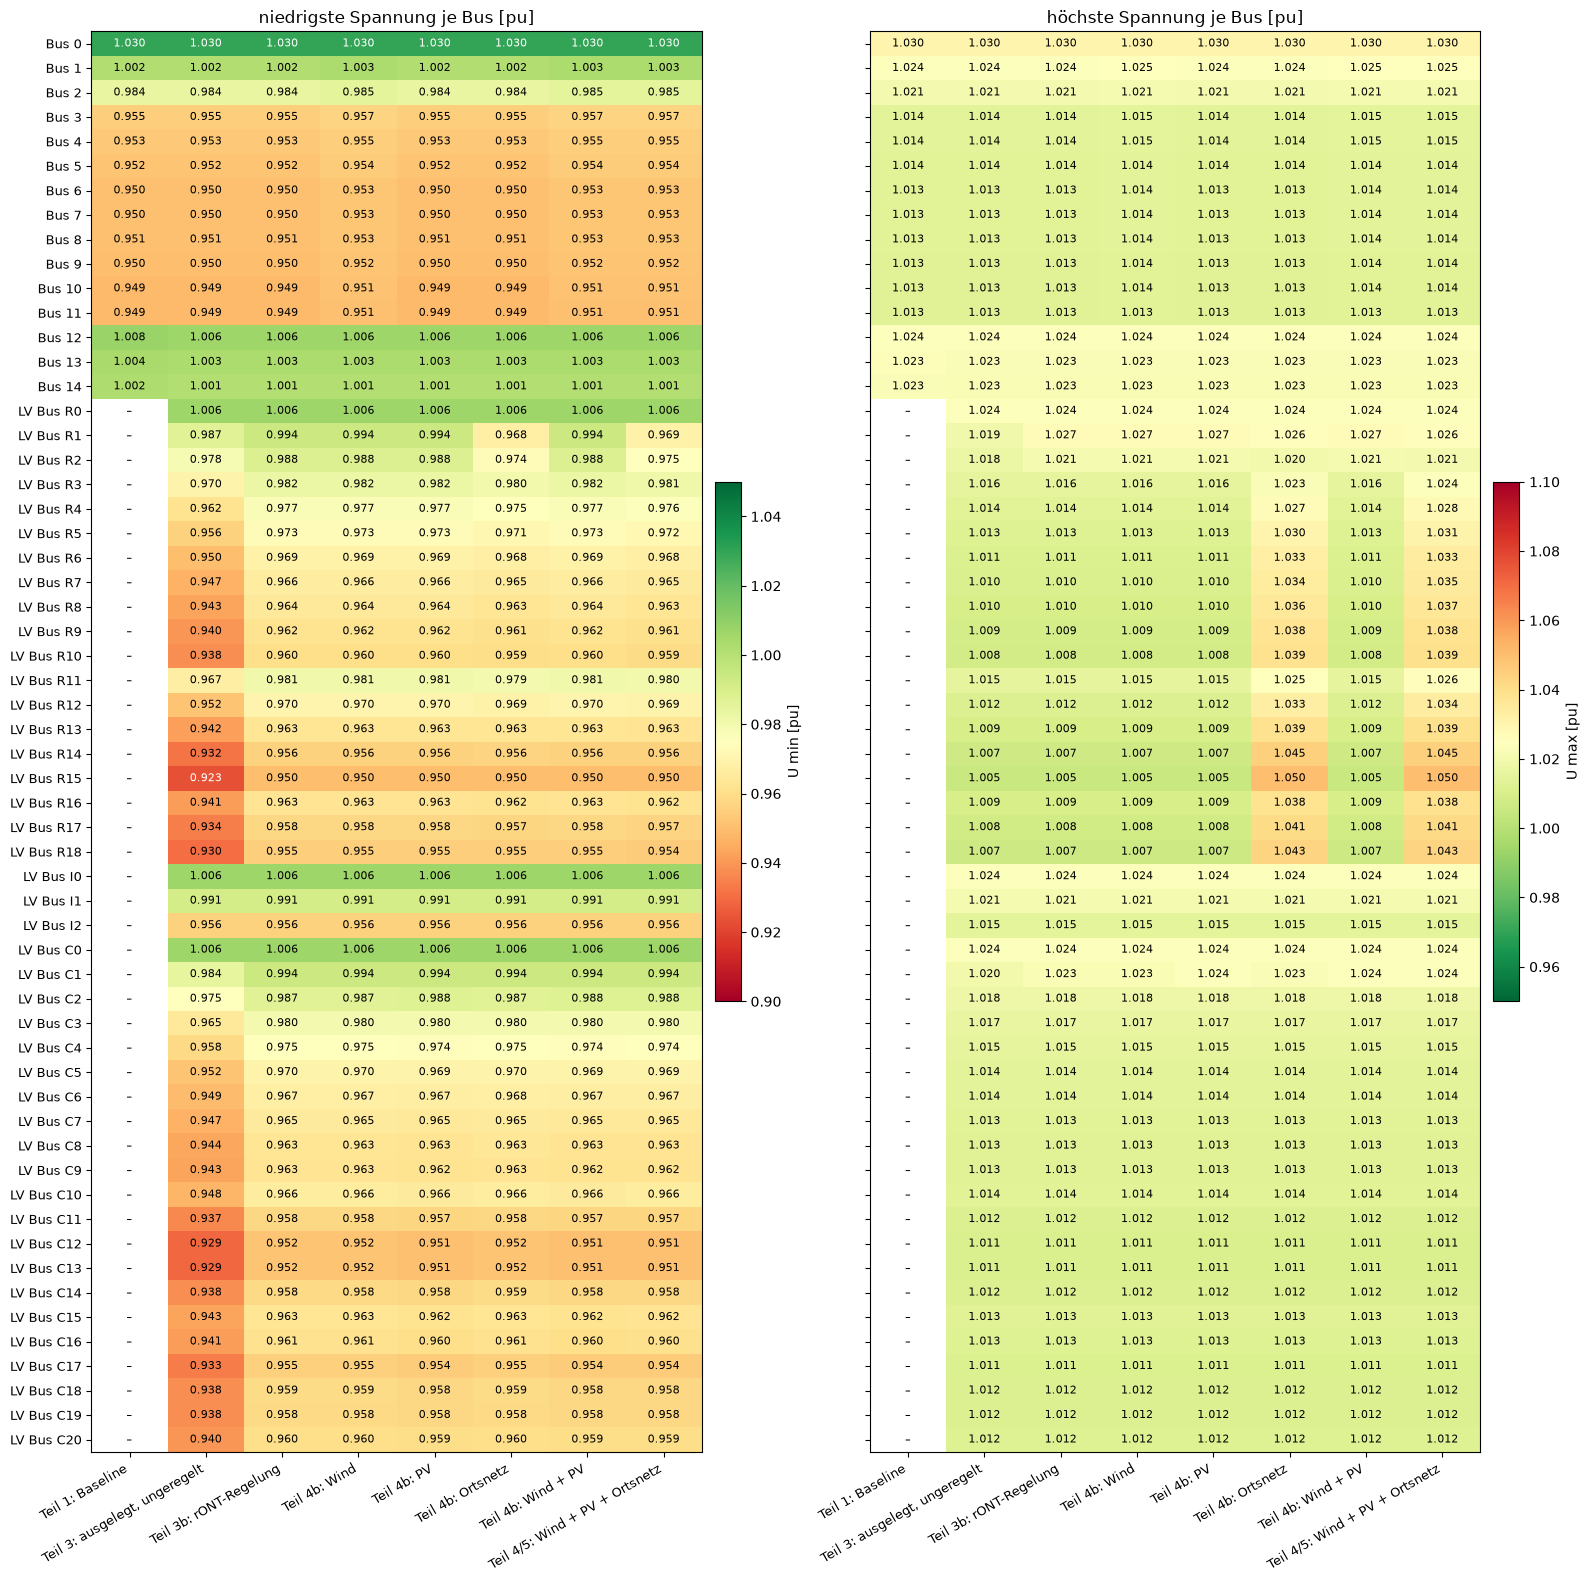

In [5]:
HAUPT = {k: v for k, v in HAUPT.items() if v in haupt}
busse = list(haupt[HAUPT["Teil 4/5: Wind + PV + Ortsnetz"]].results.vm_pu.columns)
umin = pd.DataFrame({k: stat.loc[v]["U min [pu]"] for k, v in HAUPT.items()}).reindex(busse)
umax = pd.DataFrame({k: stat.loc[v]["U max [pu]"] for k, v in HAUPT.items()}).reindex(busse)
fig, axes = plt.subplots(1, 2, figsize=(16, 0.24 * len(busse) + 2), sharey=True)
sz.heatmap(umin, "niedrigste Spannung je Bus [pu]", "U min [pu]", cmap="RdYlGn", vmin=0.90, vmax=1.05, ax=axes[0], fmt="{:.3f}")
sz.heatmap(umax, "höchste Spannung je Bus [pu]", "U max [pu]", cmap="RdYlGn_r", vmin=0.95, vmax=1.10, ax=axes[1], fmt="{:.3f}")
plt.tight_layout()
plt.show()

Spannungswinkel je Bus (größter Betrag über alle Stunden, Bezug: Slack an Bus 0 mit 0°):

In [6]:
wink = pd.DataFrame({k: stat.loc[v][["Winkel min [°]", "Winkel max [°]"]].abs().max(axis=1) for k, v in HAUPT.items()}).reindex(busse)
plots.table(wink.T, decimals=2)

Bus,Bus 0,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5,Bus 6,Bus 7,Bus 8,Bus 9,Bus 10,Bus 11,Bus 12,Bus 13,Bus 14,LV Bus R0,LV Bus R1,LV Bus R2,LV Bus R3,LV Bus R4,LV Bus R5,LV Bus R6,LV Bus R7,LV Bus R8,LV Bus R9,LV Bus R10,LV Bus R11,LV Bus R12,LV Bus R13,LV Bus R14,LV Bus R15,LV Bus R16,LV Bus R17,LV Bus R18,LV Bus I0,LV Bus I1,LV Bus I2,LV Bus C0,LV Bus C1,LV Bus C2,LV Bus C3,LV Bus C4,LV Bus C5,LV Bus C6,LV Bus C7,LV Bus C8,LV Bus C9,LV Bus C10,LV Bus C11,LV Bus C12,LV Bus C13,LV Bus C14,LV Bus C15,LV Bus C16,LV Bus C17,LV Bus C18,LV Bus C19,LV Bus C20
Teil 1: Baseline,0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.44,34.48,34.51,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
"Teil 3: ausgelegt, ungeregelt",0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.59,34.63,34.65,34.59,178.29,178.28,178.26,178.24,178.23,178.22,178.21,178.21,178.20,178.20,178.27,178.27,178.30,178.32,178.35,178.24,178.21,178.22,34.59,178.57,178.66,34.59,178.45,178.42,178.39,178.39,178.38,178.38,178.38,178.38,178.38,178.43,178.45,178.47,178.47,178.46,178.40,178.41,178.43,178.41,178.40,178.39
Teil 3b: rONT-Regelung,0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.59,34.63,34.65,34.59,178.29,178.28,178.26,178.24,178.23,178.22,178.21,178.21,178.20,178.20,178.27,178.27,178.30,178.32,178.35,178.24,178.21,178.22,34.59,178.57,178.66,34.59,178.45,178.42,178.39,178.39,178.38,178.38,178.38,178.38,178.38,178.43,178.45,178.47,178.47,178.46,178.40,178.41,178.43,178.41,178.40,178.39
Teil 4b: Wind,0.00,35.14,36.01,37.42,37.51,37.58,37.66,37.61,37.60,37.63,37.69,37.70,34.59,34.63,34.65,34.59,178.29,178.28,178.26,178.24,178.23,178.22,178.21,178.21,178.20,178.20,178.27,178.27,178.30,178.32,178.35,178.24,178.21,178.22,34.59,178.57,178.66,34.59,178.45,178.42,178.39,178.39,178.38,178.38,178.38,178.38,178.38,178.43,178.45,178.47,178.47,178.46,178.40,178.41,178.43,178.41,178.40,178.39
Teil 4b: PV,0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.59,34.63,34.65,34.59,178.49,178.46,178.43,178.40,178.38,178.36,178.34,178.33,178.32,178.31,178.44,178.45,178.50,178.55,178.59,178.40,178.35,178.35,34.59,179.06,179.18,34.59,178.91,178.87,178.82,178.82,178.81,178.81,178.81,178.80,178.80,178.87,178.90,178.93,178.93,178.91,178.84,178.84,178.87,178.85,178.83,178.81
Teil 4b: Ortsnetz,0.00,35.38,36.29,37.77,37.87,37.93,38.02,37.97,37.96,37.99,38.05,38.06,34.59,34.63,34.65,34.59,179.96,179.99,179.99,180.00,180.00,179.99,180.00,179.99,180.00,180.00,180.00,180.00,179.99,180.00,180.00,180.00,179.99,179.99,34.59,178.57,178.66,34.59,178.45,178.42,178.39,178.39,178.38,178.38,178.38,178.38,178.38,178.43,178.45,178.47,178.47,178.46,178.40,178.41,178.43,178.41,178.40,178.39
Teil 4b: Wind + PV,0.00,35.14,36.01,37.42,37.51,37.58,37.66,37.61,37.60,37.63,37.69,37.70,34.59,34.63,34.65,34.59,178.49,178.46,178.43,178.40,178.38,178.36,178.34,178.33,178.32,178.31,178.44,178.45,178.50,178.55,178.59,178.40,178.35,178.35,34.59,179.06,179.18,34.59,178.91,178.87,178.82,178.82,178.81,178.81,178.81,178.80,178.80,178.87,178.90,178.93,178.93,178.91,178.84,178.84,178.87,178.85,178.83,178.81
Teil 4/5: Wind + PV + Ortsnetz,0.00,35.14,36.01,37.42,37.51,37.58,37.66,37.61,37.60,37.63,37.69,37.70,34.59,34.63,34.65,34.59,180.00,180.00,180.00,179.98,179.99,180.00,180.00,179.98,179.98,180.00,179.99,179.99,180.00,180.00,179.98,180.00,180.00,180.00,34.59,179.19,179.31,34.59,179.04,179.00,178.96,178.95,178.95,178.94,178.94,178.94,178.94,179.01,179.04,179.07,179.07,179.04,178.97,178.98,179.01,178.99,178.96,178.95


Alle Schalterstellungen: niedrigste und höchste Spannung je Ebene (MS, NS) für jede Zeitreihengruppe in allen acht Schaltzuständen:

In [7]:
zeilen = {}
for titel, prefix in (("Teil 1: Baseline", "w4_baseline_"), ("Teil 3: ungeregelt", "w4_t3_"), ("Teil 3b: geregelt", "w4_t3r_"),
                      ("Teil 4b: Wind", "w4_t4b_wind_"), ("Teil 4b: PV", "w4_t4b_pv_"), ("Teil 4b: Ortsnetz", "w4_t4b_on_"),
                      ("Teil 4b: Wind + PV", "w4_t4b_wp_"), ("Teil 4/5: W + PV + O", "w4_t5_")):
    for k in sz.KEYS:
        n = prefix + k
        if n not in konv.index:
            continue
        st = stat.loc[n]
        for eb in ("MS", "NS"):
            e = st[st["Ebene"] == eb]
            if len(e):
                zeilen[(titel, sz.label(k, kurz=True))] = zeilen.get((titel, sz.label(k, kurz=True)), {}) | {
                    f"U min {eb}": e["U min [pu]"].min(), f"U max {eb}": e["U max [pu]"].max()}
ebenen = pd.DataFrame(zeilen).T
plots.table(ebenen, decimals=3)

**Befund Spannungen an allen Bussen:**

- **Normalbetrieb:** In allen Hauptszenarien und allen acht Schaltzuständen bleiben alle 54 MS- und NS-Busse in jeder Stunde innerhalb der Arbeitsgrenzen. Mit rONT-Regelung liegt die NS-Spannung zwischen 0,950 und 1,050 pu. Die MS-Spannung sinkt bei offenem S1 an Bus 11 bis 0,949 pu (8 Stunden unter dem Planungsband); mit Windpark oder geschlossenem S1 bleibt sie über 0,95 pu.
- **Verletzungen der Arbeitsgrenzen** gibt es nur in Varianten, die bewusst verworfen oder als Grenzfall untersucht wurden: Ortsnetz an Bus 2 bis 11 (Teil 2, bis 0,85 pu), Windpark in den Abgängen (Teil 4a, bis 1,23 pu), PV-Haushalte Variante Zukunft (Teil 4b, bis 1,20 pu), Windpark mit cos φ = 0,95 untererregt (Teil 4b, 0,89999 pu in einer Stunde) und Trafoausfall mit S1 (Teil 5, 0,40 bis 1,25 pu).
- **Winkel:** Im MS-Netz liegen die Winkel zwischen −31° und −38°, weil die Trafos 110/20 kV der CIGRE-Daten eine Phasendrehung von 30° haben (`shift_degree`, Schaltgruppe). Dazu kommt der Lastwinkel: 1 bis 5° an Bus 1, bis 8° am Ende von Abgang 1. Die NS-Busse liegen um rund 150° weiter gedreht (Schaltgruppe der Ortsnetztrafos, Dyn5). Die Änderung durch Last und Einspeisung beträgt nur einige Zehntel bis wenige Grad: Der Windpark verringert die Winkel in Abgang 1 um etwa 0,3°, weil er dort Wirkleistung einspeist.
- **Vollständige Werte:** Die Tabelle `ergebnisse/spannungen_alle_busse.csv` enthält für jede der 141 Zeitreihen und jeden Bus U min, U mittel, U max, die Winkel und die Stunden außerhalb der Bänder.

## 5 Leistungsbilanz und Verluste

Für jede Stunde muss gelten: Bezug aus dem 110-kV-Netz = Last + Speicherladung − Einspeisung + Verluste. Die Abweichung zeigt, ob die Ergebnisse vollständig erfasst sind (Prüfung für die Hauptszenarien, Normalschaltzustand):

In [8]:
def bilanz(s):
    r = s.results
    ok = r.converged.astype(bool)
    last = r.load_p_mw[ok].sum(axis=1)
    sto = r.storage_p_mw[ok].sum(axis=1) if r.storage_p_mw.shape[1] else 0 * last
    erz = r.sgen_p_mw[ok].sum(axis=1)
    verl = r.line_pl_mw[ok].sum(axis=1) + r.trafo_pl_mw[ok].sum(axis=1)
    ext = r.ext_grid_p_mw[ok].sum(axis=1)
    rest = ext - (last + sto - erz + verl)
    return {"Last [MWh]": last.sum(), "Speicher netto [MWh]": sto.sum(), "Einspeisung [MWh]": erz.sum(),
            "Verluste [MWh]": verl.sum(), "Verluste [% der Last]": 100 * verl.sum() / last.sum(),
            "Bezug 110 kV netto [MWh]": ext.sum(), "Rückspeisung 110 kV [MWh]": (-ext).clip(lower=0).sum(),
            "größte Abweichung der Bilanz [kW]": 1000 * rest.abs().max()}

plots.table(pd.DataFrame({k: bilanz(haupt[v]) for k, v in HAUPT.items()}).T, decimals=2)

,Last [MWh],Speicher netto [MWh],Einspeisung [MWh],Verluste [MWh],Verluste [% der Last],Bezug 110 kV netto [MWh],Rückspeisung 110 kV [MWh],größte Abweichung der Bilanz [kW]
Teil 1: Baseline,43721.95,0.00,0.00,140.88,0.32,43862.83,0.00,0.00
"Teil 3: ausgelegt, ungeregelt",44372.58,0.00,0.00,162.98,0.37,44535.56,0.00,0.00
Teil 3b: rONT-Regelung,44372.58,0.00,0.00,162.80,0.37,44535.38,0.00,0.00
Teil 4b: Wind,44372.58,0.00,17370.78,154.88,0.35,27156.69,1471.63,0.00
Teil 4b: PV,44372.58,0.00,2813.71,159.51,0.36,41718.39,0.00,0.00
Teil 4b: Ortsnetz,44372.58,3.66,214.42,161.29,0.36,44323.12,0.00,0.00
Teil 4b: Wind + PV,44372.58,0.00,20184.49,151.60,0.34,24339.70,1566.11,0.00
Teil 4/5: Wind + PV + Ortsnetz,44372.58,3.66,20398.91,150.22,0.34,24127.56,1578.80,0.00


**Befund Leistungsbilanz:** Die Bilanz aus Bezug, Last, Speicher, Einspeisung und Verlusten geht in jeder Stunde auf (Abweichung 0,0 kW); die Ergebnistabellen sind also vollständig. Die Verluste liegen bei 0,32 % der Last ohne Ortsnetz und 0,37 % mit Ortsnetz. Mit Erzeugern sinken sie auf 0,34 %, weil weniger Leistung über die Leitungen transportiert werden muss: Windpark und PV-Anlage speisen an den Sammelschienen ein, und ihr Überschuss fließt nur über die Trafos. Der Windpark erzeugt in den 12 Wochen 17,4 GWh, das sind 39 % der Last; davon fließen 1,5 GWh ins 110-kV-Netz zurück.

## 6 Beobachtung und physikalische Erklärung

Die wichtigsten Beobachtungen aus Teil 1 bis 6 und ihre Erklärung. Grundlage ist der Spannungsfall längs einer Leitung mit Resistanz R und Reaktanz X, die die Wirkleistung P und die Blindleistung Q überträgt [19]:

$$\Delta U \approx \frac{R \cdot P + X \cdot Q}{U}$$

Fließt Leistung zum Verbraucher, sinkt die Spannung entlang der Leitung; kehrt sich der Fluss um (Einspeisung größer als Last), steigt sie. In Kabelnetzen der Mittel- und Niederspannung ist R/X groß, deshalb wirkt dort vor allem die Wirkleistung; Blindleistung wirkt umso stärker, je größer X ist (Freileitungen, Transformatoren).

| Beobachtung (Teil) | physikalische Erklärung |
|---|---|
| Die Spannung sinkt in Abgang 1 ab Bus 3 auf 0,95 pu, Abgang 2 bleibt über 1,00 pu (Teil 1, 2) | Abgang 1 trägt den größten Teil der Last über lange Kabel (Line 1-2, 2-3 mit zusammen 7,2 km). Der Spannungsfall R·P + X·Q wächst mit Leistung und Länge. Abgang 2 ist schwach belastet. |
| Das Ortsnetz verliert bei 0,4 kV prozentual mehr Spannung und Leistung als das MV-Netz (Teil 2) | Für dieselbe Leistung fließt bei 0,4 kV der 50-fache Strom. Die Verluste wachsen mit I², der Spannungsfall mit I·Z. Hinzu kommt der Spannungsfall im Ortsnetztrafo (Kurzschlussspannung). |
| Das Schließen von S1 entlastet Abgang 1 und senkt die Verluste um etwa 21 % (Teil 1, 3) | In der Masche über beide Transformatoren teilt sich der Fluss umgekehrt proportional zu den Impedanzen auf [19, S. 437 f.]. Ein Teil der Last von Abgang 1 wird über Trafo 0-12 und Abgang 2 versorgt, der Strom auf Line 1-2/2-3 sinkt, die Verluste sinken mit I². |
| Der rONT hebt mit einer Stufe alle Busse seines Teilnetzes um etwa 2,5 % an, hat aber keine Wirkung auf das MV-Netz und die anderen Teilnetze (Teil 3b) | Die Stufe ändert die Übersetzung des Trafos: Die Unterspannung wird bei gleicher Oberspannung um 2,5 % verschoben. Die Leistung des Teilnetzes ändert sich dabei kaum, deshalb bleibt der Fluss im MV-Netz fast gleich. |
| Windpark und PV-Anlage überlasten die Abgänge, an den Trafo-Sammelschienen nicht (Teil 4a) | Die Kabel der Abgänge sind für etwa 5 MVA ausgelegt. An der Sammelschiene fließt die Einspeisung direkt über den 110/20-kV-Trafo ab und belastet keine MS-Leitung. |
| Bei starkem Wind fließt Leistung ins 110-kV-Netz zurück; die Trafoauslastung steigt dann wieder (Teil 4, 5) | Die Auslastung hängt vom Betrag des Stroms ab, nicht von der Richtung. Übersteigt die Einspeisung die Last hinter dem Trafo, kehrt sich p_hv_mw um und der Strom wächst mit dem Überschuss. |
| Im Wohngebiet speisen die PV-Haushalte mittags über den Ortsnetztrafo zurück, die Spannung an den Strangenden steigt und der rONT regelt nach unten (Teil 4b, 5) | Mit umgekehrtem Fluss wird R·P negativ: Die Spannung steigt zum Strangende hin. Der Speicher nimmt nur einen Teil des Überschusses auf, weil er nach einigen Stunden voll ist. |
| Blindleistungsbezug der Erzeuger (cos φ = 0,95 untererregt) senkt die Spannung nur wenig (Teil 4b) | Der Beitrag X·Q ist in Kabelnetzen mit großem R/X klein. Die Erzeuger hängen an den Trafo-Sammelschienen, deshalb wirkt Q vor allem über die Reaktanz der Transformatoren. |
| Line 3-8 wird nur durch Einspeisung an Bus 8 zuerst überlastet, nicht durch Last (Teil 6) | Im Strahlennetz trägt jede Leitung die Summe der Leistungen dahinter. Line 2-3 und 1-2 liegen vor Line 3-8 und tragen bei Last immer mehr. Eine Einspeisung an Bus 8 fließt dagegen zuerst über Line 3-8 zurück. |
| Ein stärkeres Kabel auf Line 3-8 verlagert den Engpass auf Line 2-3 (Teil 6) | Die Leistung muss weiter über Line 2-3 und 1-2 zum Umspannwerk fließen. In vermaschten Zuständen zieht die Leitung mit kleinerer Impedanz zusätzlich Leistung an. |

## 7 Annahmen und Daten

| Bereich | Annahme | Quelle bzw. Ort der Begründung |
|---|---|---|
| Netz | CIGRE-MV-Benchmarknetz `with_der=False`, CIGRE-LV-Netz als Ortsnetz an Bus 12 | [13], [14]; Teil 1 und 2 |
| Zeitauflösung | 12 typische Wochen (eine je Monat), Stundenwerte, 2016 Lastflüsse je Zeitreihe | Datengrundlage, Abschnitt 1 |
| Lasten | BDEW-Standardlastprofile H25, G25, L25, skaliert auf die CIGRE-Bemessungsleistung; cos φ der CIGRE-Lasten | [1]; Datengrundlage |
| Ortsnetzprofil aus W2 | nicht verwendet, weil in W2 kein Ortsnetzprofil erstellt wurde; stattdessen Standardlastprofile und PV-Haushalte | – |
| Wetter | Wind- und Strahlungsdaten 2025 (stündlich), dieselben Wochen wie die Lastprofile | Datengrundlage, Abschnitt 1 |
| Windpark | 15 WEA Vestas V90-2.0 MW, zusammen 30 MW, ein Erzeuger mit gemeinsamer Windgeschwindigkeit, cos φ = 1 (Variante 0,95 untererregt in Teil 4b) | Datengrundlage 1.2; Teil 4a; [31] |
| PV-Freifläche | 10 MWp, Einspeiseprofil aus der Globalstrahlung, cos φ = 1 (Variante 0,95 in Teil 4b) | [22]; Teil 4a; [31] |
| PV-Haushalte | 3000 kWh/a je Haushalt, 9 kWp, Speicher 8,3 kWh und 4,9 kW, Wirkungsgrad 0,95 je Richtung; heute 15 % der Haushalte mit PV (6,7 % mit Speicher), Zukunft 50 % (40 %) | [23], [24], [32] bis [38]; Datengrundlage, Abschnitt 1.6 |
| Spannungsband | Arbeitsgrenzen 0,90 … 1,10 pu, Planungsband 0,95 … 1,05 pu | [15]; Teil 3, Abschnitt 1 |
| rONT | Stufenschalter auf der Oberspannungsseite, ±2 Stufen à 2,5 %, Messung im eigenen Teilnetz | [20], [21]; Teil 3b |
| Leitungsgrenzen | `max_i_ka` aus den Standardtypen bzw. Datenblättern | [18], [25], [26]; Teil 2 und 6 |

Das vollständige Quellenverzeichnis steht im Notebook `Task4-Datengrundlage.ipynb`, Abschnitt 3.

## 8 Modellgrenzen

- **Stationär und symmetrisch:** Es werden nur symmetrische AC-Lastflüsse berechnet. Unsymmetrie durch einphasig angeschlossene PV-Anlagen und Lasten im Ortsnetz, Oberschwingungen, Flicker und Kurzschlussströme sind nicht abgebildet.
- **Stundenwerte und Standardprofile:** Kurzzeitige Spitzen einzelner Kunden und schnelle Wolkenzüge mitteln sich heraus. Standardlastprofile beschreiben viele Haushalte im Mittel, nicht den einzelnen Anschluss. Echte Spitzen sind höher, die Spannungsbandverletzungen deshalb eher unterschätzt.
- **Typische Wochen:** 12 Wochen stehen für ein Jahr. Seltene Extremsituationen (Windflaute bei Kälte, Starkwind bei Schwachlast) können fehlen. Absolute Jahreswerte (Energie, Schalthandlungen) sind Hochrechnungen.
- **Regelung idealisiert:** Der Stufenschalter reagiert innerhalb derselben Stunde, ohne Totzeit und ohne Verschleiß. Die Wiederversorgung schaltet sofort und ohne Schutztechnik.
- **Speicher:** Fester Eigenverbrauchsfahrplan ohne Prognose und ohne netzdienliche Steuerung. Der Ladezustand startet in jeder typischen Woche bei 0 %. Alterung und Standby-Verluste sind nicht berücksichtigt.
- **Netzrand:** Das 110-kV-Netz ist ein starres Netz (Slack mit 1,03 pu). Rückwirkungen auf das überlagerte Netz sind nicht abgebildet.
- **Leitungsgrenzen:** Die thermische Grenze ist ein fester Dauerstrom. Kurzzeitige Überlastbarkeit und Witterungsabhängigkeit (Freileitungsmonitoring) sind nicht berücksichtigt.
- **CIGRE-Parameter:** Einige Werte des Benchmarknetzes weichen von realen Betriebsmitteln ab, z. B. der hohe Leitungsbelag X′ der MS-Kabel (Teil 6). Die Ergebnisse gelten für dieses Referenznetz und sind nicht direkt auf reale Netze übertragbar.

### Quellen

Nummern wie im zentralen Quellenverzeichnis (`Task4-Datengrundlage.ipynb`, Abschnitt 3).

[1] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Hinweise zu den aktualisierten Standardlastprofilen Strom“, Anwendungshilfe, Berlin, 17.03.2025. Online: https://bdew.de/media/documents/2025-03-17_AWH_Aktualisierte_SLP_Strom_2025_Ver%C3%B6ffentlichung.pdf

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[14] L. Thurner et al., „pandapower – An Open-Source Python Tool for Convenient Modeling, Analysis, and Optimization of Electric Power Systems“, IEEE Transactions on Power Systems, Bd. 33, Nr. 6, S. 6510–6521, Nov. 2018, doi: 10.1109/TPWRS.2018.2829021.

[15] DIN EN 50160, „Merkmale der Spannung in öffentlichen Elektrizitätsversorgungsnetzen“ (EN 50160:2010 mit Änderungen), Berlin: Beuth.

[17] pandapower, „Datastructure and Elements“, Dokumentation der Elemente und Ergebnistabellen (res_bus, res_line, res_trafo, res_ext_grid, res_storage). Online: https://pandapower.readthedocs.io/en/latest/elements.html

[18] *Smart Energy Management for Smart Grid*, Basel: MDPI Books, Tabelle der Leitungstypen des CIGRE-LV-Netzes (Querschnitt, R und L von Phasen- und Neutralleiter, Bemessungsstrom). Online: https://mdpi-res.com/bookfiles/book/7980/Smart_Energy_Management_for_Smart_Grid.pdf

[19] A. J. Schwab, *Elektroenergiesysteme: Erzeugung, Transport, Übertragung und Verteilung elektrischer Energie*, 3. Aufl. Berlin, Heidelberg: Springer, 2012, doi: 10.1007/978-3-642-21958-0.

[20] Maschinenfabrik Reinhausen, „Regelbarer Ortsnetztransformator“, Vortrag, Lehrstuhl für Elektrische Energiesysteme, FAU Erlangen-Nürnberg. Online: https://www.ees.tf.fau.de/files/2017/12/MR_Regelbarer_Ortsnetztrafo.pdf

[21] Maschinenfabrik Reinhausen, „ECOTAP VPD (24 kV)“, Produktinformation. Online: https://www.reinhausen.com/fileadmin/downloadcenter/products/oltc/ecotap_vpd/flyer/ecotap_vpd_24kv_de.pdf

[22] C. Kost et al., „Stromgestehungskosten Erneuerbare Energien“, Fraunhofer ISE, Freiburg, Juni 2021, Tabelle 3, S. 14. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/DE2021_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf

[23] KfW Research, „Fast 13 Millionen Haushalte nutzen Energiewendetechnologien“, Pressemitteilung, 12.09.2024 (KfW-Energiewendebarometer). Online: https://www.kfw.de/%C3%9Cber-die-KfW/Newsroom/Aktuelles/Pressemitteilungen-Details_821696.html

[24] Fraunhofer ISE, „Photovoltaics Report“, Freiburg. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/Photovoltaics-Report.pdf

[25] pandapower, „Standard Type Libraries“ und `create_cigre_network_mv`, Dokumentation, Version 3.x. Online: https://pandapower.readthedocs.io

[26] Zuhmann, „Mittelspannungskabel NA2XS2Y nach VDE 0276-620“, Datenblatt (Ausgabe 13.07.2016). Online: https://www.zuhmann.info/media/daten/019.pdf

[31] VDE-AR-N 4110, „Technische Regeln für den Anschluss von Kundenanlagen an das Mittelspannungsnetz und deren Betrieb (TAR Mittelspannung)“, Berlin: VDE Verlag, 2023.

[32] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Stromverbrauch vergleichen und Sparpotenzial nutzen“, Presseinformation, 21.04.2016. Online: https://www.bdew.de/presse/presseinformationen/stromverbrauch-vergleichen-und-sparpotenzial-nutzen/

[38] HTW Berlin, „Stromspeicher-Inspektion 2021“, Berlin, 2021. Online: https://solar.htw-berlin.de/wp-content/uploads/HTW-Stromspeicher-Inspektion-2021.pdf
